In [ ]:
# @title Mounting Google Drive
from google.colab import drive


# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install opencv-python
!pip install ffmpeg-python

In [ ]:
# @title Libraries
from typing import Mapping
import os
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import librosa
import matplotlib.pyplot as plt
from torch import optim
import time
import shutil
import random
import matplotlib.axes as ax
import pandas as pd
import seaborn as sn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [ ]:
# @title Constants
class_to_int = {
    'neutral' : 0,
    'calm' : 1,
    'happy' : 2,
    'sad': 3,
    'angry': 4,
    'fearful': 5,
    'disgust': 6,
    'surprised': 7
}

int_to_class = {v: k for k, v in class_to_int.items()}

data_pth = '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/combined'
arr_pth = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/RAVDESS'

#data_pth = '/content/drive/MyDrive/COSMOSPosterProject/CREMA_D/combined'
#arr_pth = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D'


SAMPLE_RATE = 48000

train_arrs = os.path.join(arr_pth, 'train_arrs')
test_arrs = os.path.join(arr_pth, 'test_arrs')

In [ ]:
len(os.listdir('/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/AudioWAV'))

7442

In [ ]:
len(os.listdir('/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/VideoFlash'))

7452

In [ ]:
data_pth = '/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET'
audio_pth = os.path.join(data_pth, 'AudioWAV')
video_pth = os.path.join(data_pth, 'VideoMP4')
combined_pth = os.path.join(data_pth, 'combined', 'test_arrs')
emotions = [150]*6
emo_dict = {
    'NEU': 0,
    'HAP': 1,
    'SAD': 2,
    'ANG': 3,
    'FEA': 4,
    'DIS': 5,
}
num = 0
for audio_file in os.listdir(audio_pth):
    for video_file in os.listdir(video_pth):
        audio_name = audio_file.split('.')[0]
        video_name = video_file.split('.')[0]
        if (audio_name == video_name):
            emotion = audio_name.split('_')[2]
            if (emotions[emo_dict[emotion]] > 0):
                print(audio_name)
                emotions[emo_dict[emotion]] -= 1
                num += 1
                print(num)
                print(emotions)
                emo_pth = os.path.join(combined_pth, emotion)
                print(emo_pth)

                os.makedirs(os.path.join(emo_pth, audio_name), exist_ok=True)
                old_audio_pth = os.path.join(audio_pth, audio_name + '.wav')
                print(old_audio_pth)
                old_video_pth = os.path.join(video_pth, video_name + '.mp4')
                print(old_video_pth)

                new_folder = os.path.join(emo_pth, audio_name)
                shutil.move(old_audio_pth, os.path.join(new_folder, audio_name + '.wav'))
                shutil.move(old_video_pth, os.path.join(new_folder, video_name + '.mp4'))


                print('---------------')
            break
    if (num == 900):
        break
print(num)

In [ ]:
data_pth = '/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET'
combined_pth = os.path.join(data_pth, 'combined', 'test_arrs')
for emo in os.listdir(combined_pth):
    curr_pth = os.path.join(combined_pth, emo)
    for pair in os.listdir(curr_pth):
        print(os.listdir(os.path.join(curr_pth, pair)))

['1079_IWW_FEA_XX.wav', '1079_IWW_FEA_XX.mp4']
['1080_DFA_FEA_XX.wav', '1080_DFA_FEA_XX.mp4']
['1079_IOM_FEA_XX.wav', '1079_IOM_FEA_XX.mp4']
['1079_IEO_FEA_MD.wav', '1079_IEO_FEA_MD.mp4']
['1079_IEO_FEA_HI.wav', '1079_IEO_FEA_HI.mp4']
['1079_DFA_FEA_XX.wav', '1079_DFA_FEA_XX.mp4']
['1080_ITS_FEA_XX.wav', '1080_ITS_FEA_XX.mp4']
['1080_WSI_FEA_XX.wav', '1080_WSI_FEA_XX.mp4']
['1080_ITH_FEA_XX.wav', '1080_ITH_FEA_XX.mp4']
['1080_TIE_FEA_XX.wav', '1080_TIE_FEA_XX.mp4']
['1080_IWL_FEA_XX.wav', '1080_IWL_FEA_XX.mp4']
['1081_ITS_FEA_XX.wav', '1081_ITS_FEA_XX.mp4']
['1080_IOM_FEA_XX.wav', '1080_IOM_FEA_XX.mp4']
['1080_IWW_FEA_XX.wav', '1080_IWW_FEA_XX.mp4']
['1080_TSI_FEA_XX.wav', '1080_TSI_FEA_XX.mp4']
['1080_TAI_FEA_XX.wav', '1080_TAI_FEA_XX.mp4']
['1081_IOM_FEA_XX.wav', '1081_IOM_FEA_XX.mp4']
['1081_IEO_FEA_MD.wav', '1081_IEO_FEA_MD.mp4']
['1081_DFA_FEA_XX.wav', '1081_DFA_FEA_XX.mp4']
['1080_MTI_FEA_XX.wav', '1080_MTI_FEA_XX.mp4']
['1081_IEO_FEA_HI.wav', '1081_IEO_FEA_HI.mp4']
['1081_ITH_FE

In [ ]:
import os
import ffmpeg  # uses ffmpeg-python, not the raw CLI

# Input and output directories
input_dir = '/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/VideoFlash'
output_dir = '/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/VideoMP4'
os.makedirs(output_dir, exist_ok=True)

# Loop through all .flv files
for filename in os.listdir(input_dir):
    if filename.endswith(".flv"):
        input_path = os.path.join(input_dir, filename)
        output_filename = os.path.splitext(filename)[0] + ".mp4"
        output_path = os.path.join(output_dir, output_filename)

        print(f"Converting {filename} → {output_filename}")

        try:
            (
                ffmpeg
                .input(input_path)
                .output(output_path, vcodec='libx264', acodec='aac', strict='experimental')
                .run(overwrite_output=True, quiet=True)
            )
        except ffmpeg.Error as e:
            print(f"❌ Failed to convert {filename}: {e.stderr.decode()}")

print("✅ All .flv files converted to .mp4!")

Streaming output truncated to the last 5000 lines.
Converting 1027_ITH_ANG_XX.flv → 1027_ITH_ANG_XX.mp4
Converting 1050_WSI_DIS_XX.flv → 1050_WSI_DIS_XX.mp4
Converting 1047_ITH_SAD_XX.flv → 1047_ITH_SAD_XX.mp4
Converting 1076_TIE_NEU_XX.flv → 1076_TIE_NEU_XX.mp4
Converting 1021_TIE_ANG_XX.flv → 1021_TIE_ANG_XX.mp4
Converting 1045_DFA_DIS_XX.flv → 1045_DFA_DIS_XX.mp4
Converting 1008_IWW_ANG_XX.flv → 1008_IWW_ANG_XX.mp4
Converting 1041_IEO_NEU_XX.flv → 1041_IEO_NEU_XX.mp4
Converting 1052_ITH_SAD_XX.flv → 1052_ITH_SAD_XX.mp4
Converting 1063_TIE_NEU_XX.flv → 1063_TIE_NEU_XX.mp4
Converting 1072_IWW_DIS_XX.flv → 1072_IWW_DIS_XX.mp4
Converting 1054_IEO_NEU_XX.flv → 1054_IEO_NEU_XX.mp4
Converting 1040_ITH_FEA_XX.flv → 1040_ITH_FEA_XX.mp4
Converting 1009_IEO_FEA_LO.flv → 1009_IEO_FEA_LO.mp4
Converting 1034_TIE_ANG_XX.flv → 1034_TIE_ANG_XX.mp4
Converting 1067_IWW_DIS_XX.flv → 1067_IWW_DIS_XX.mp4
Converting 1028_IEO_HAP_LO.flv → 1028_IEO_HAP_LO.mp4
Converting 1023_IEO_DIS_HI.flv → 1023_IEO_DIS_HI

In [ ]:
video_path = '/content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/AudioWAV'
file = '1064_IEO_DIS_MD.wav'
os.remove(os.path.join(video_path, file))

In [ ]:

# @title Data Preprocessing
def add_noise(signal, num_bits=16, augmented_num=2, snr=30):
    signal_len = len(signal)
    # Generate White Gaussian noise
    noise = np.random.normal(size=(augmented_num, signal_len))
    # Normalize signal and noise
    norm_constant = 2.0**(num_bits-1)
    signal_norm = signal / norm_constant
    noise_norm = noise / norm_constant
    # Compute signal and noise power
    s_power = np.sum(signal_norm ** 2) / signal_len
    n_power = np.sum(noise_norm ** 2, axis=1) / signal_len
    # Random SNR: Uniform [15, 30] in dB
    target_snr = os.ST_NODIRATIME
    # Compute K (covariance matrix) for each noise
    K = np.sqrt((s_power / n_power) * 10 ** (- target_snr / 10))
    K = np.ones((signal_len, augmented_num)) * K
    # Generate noisy signal
    return signal + K.T * noise

def add_noise_image(image, mean=0, var=0.01):
    image_arr = np.array(image)
    sigma = np.sqrt(var)

    # Generate Gaussian noise
    gauss_noise = np.random.normal(mean, sigma, image_arr.shape)

    # Add noise to the image
    noisy_image_array = image_arr + gauss_noise

    # Clip the values to be in valid range
    noisy_image_array = np.clip(noisy_image_array, 0, 255)

    noisy_image = Image.fromarray(np.uint8(noisy_image_array))

    return noisy_image

# Define the transforms for grayscale images
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

folder = 'test'

root_dir = data_pth + f'/{folder}'
transform = transform
classes = os.listdir(root_dir)
class_to_idx = class_to_int
video_files = []
audio_files = []
labels = []
max_frames = 35
offset = 0
noise_add = False
noise_idx = 0
sound_snr = 5
image_var = 0.5

for class_name in classes:
    class_dir = os.path.join(root_dir, class_name)
    if os.path.isdir(class_dir):
        for mini_dir in os.listdir(class_dir):
            mini_path = os.path.join(class_dir, mini_dir)
            #print(mini_dir)
            files = os.listdir(mini_path)
            if files[0].endswith('.mp4'):
                video_files.append(os.path.join(mini_path, files[0]))
                audio_files.append(os.path.join(mini_path, files[1]))
                labels.append(class_to_idx[class_name])
            else:
                video_files.append(os.path.join(mini_path, files[1]))
                audio_files.append(os.path.join(mini_path, files[0]))
                labels.append(class_to_idx[class_name])

min_total_frames = 10000000
total_frames = 0

def get_vid(video_path):
    global min_total_frames
    global total_frames
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    min_total_frames = min(min_total_frames, total_frames)

    frames = []
    t = time.time()

    curr_frame_idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if (curr_frame_idx%2 != 0):
            curr_frame_idx += 1
            continue
        # Convert frame to grayscale
        RGB_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        faces = face_cascade.detectMultiScale(RGB_frame, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
        if len(faces) > 0:
            # Sort faces by size (largest face first)
            faces = sorted(faces, key=lambda x: x[2] * x[3], reverse=True)

            # Take the first detected face (largest face)
            (x, y, w, h) = faces[0]

            # Crop the face region from the frame
            face = frame[y:y+h, x:x+w]

            # Convert to PIL Image for transformation
            pil_face = Image.fromarray(face)

            if transform:
                face_tensor = transform(pil_face)
                face_tensor = torch.squeeze(face_tensor)  # Remove single-dimensional entries
                frames.append(face_tensor)
        curr_frame_idx += 1
        if (len(frames) == max_frames):
            break
    cap.release()

    frames = torch.stack(frames)
    frames = frames.permute(1, 0, 2, 3)

    return frames

def get_spec(path):
    t = time.time()
    audio, sample_rate = librosa.load(path, duration=3, sr=SAMPLE_RATE)
    signal = np.zeros((int(SAMPLE_RATE*3, )))
    signal[:len(audio)] = audio
    if (noise_add):
        signal = add_noise(signal)[noise_idx]
    mel_spec = librosa.feature.melspectrogram(y=signal, sr=sample_rate, n_fft=1024, win_length = 512, window='hamming', hop_length = 256, n_mels=128, fmax=sample_rate/2)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

    #print(mel_spec_db.shape)
    #plt.figure(figsize=(12, 4))
    #librosa.display.specshow(mel_spec_db, sr=SAMPLE_RATE, x_axis='time', y_axis='hz')
    #plt.colorbar(format='%+2.0f dB')
    #plt.title('Spectrogram')
    #plt.show()

    #print("Time Audio: " + str(time.time() - t))
    return torch.tensor(mel_spec_db)

cntr = 0
print(len(video_files))
for i in range(len(video_files)):
    cntr += 1
    print(f"Vid Path: {video_files[i]}")
    print(f"Audio Path: {audio_files[i]}")
    print(f"Label: {int_to_class[labels[i]]}")
    video_path = video_files[i]
    audio_path = audio_files[i]
    label = labels[i]
    frames = get_vid(video_path)
    print(f"Current minimum frames: {min_total_frames}")
    print(f"Current frames: {total_frames}")
    print(f"Current data #: {i}")
    print('-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------')
    spec = get_spec(audio_path)
    print(spec.shape)
    torch.save(spec, arr_pth + f'/{folder}/audio/spec_{i}.pt')
    torch.save(frames, arr_pth + f'/{folder}/video/video_{i}.pt')
    torch.save(label, arr_pth + f'/{folder}/label/label_{i}.pt')
print(cntr)

Streaming output truncated to the last 5000 lines.
Audio Path: /content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/combined/test/neutral/1091_IEO_NEU_XX/1091_IEO_NEU_XX.wav
Label: neutral
Current minimum frames: 41
Current frames: 56
Current data #: 298
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
torch.Size([128, 563])
Vid Path: /content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/combined/test/neutral/1091_WSI_NEU_XX/1091_WSI_NEU_XX.mp4
Audio Path: /content/drive/MyDrive/COSMOSPosterProject/CREMA_D_DATASET/combined/test/neutral/1091_WSI_NEU_XX/1091_WSI_NEU_XX.wav
Label: neutral
Current minimum frames: 41
Current frames: 71
Current data #: 299
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
torch.Size([128, 563])
Vid Path

In [ ]:
def remove_all_files(idx, root_dir):
    for medium in os.listdir(root_dir):
        path = os.path.join(root_dir, medium)
        front = os.listdir(path)[0].split('_')[0]
        try:
            os.remove(os.path.join(path, f'{front}_{idx}.pt'))
            print(f"Removing: {os.path.join(path, f'{front}_{idx}.pt')}")
        except:
            pass

In [ ]:
root_dir = arr_pth + '/test'
video = [x.split('_')[1].split('.')[0] for x in os.listdir(root_dir + '/video')]
other = [x.split('_')[1].split('.')[0] for x in os.listdir(root_dir + '/label')]
print(list(set(other) - set(video)))
print(list(set(video) - set(other)))

[]
[]


In [ ]:
bad_files = []
root_dir = arr_pth + '/test'

for fname in os.listdir(root_dir + '/video'):
    if not fname.endswith('.pt'):
        continue
    try:
        print(os.path.join(root_dir + '/video', fname))
        frames = torch.load(os.path.join(root_dir + '/video', fname))
        #print(frames.shape)
        number = fname.split('.')[0].split('_')[1]
        if frames.shape != (3, 35, 224, 224):
            remove_all_files(number, root_dir)
            print(f"Bad shape: {frames.shape} in {fname}")
            bad_files.append(fname)
    except Exception as e:
        print(f"Failed to load {fname}: {e}")
        bad_files.append(fname)
        remove_all_files(number, root_dir)

print(f"\nFound {len(bad_files)} bad files:")
for f in bad_files:
    print(f)

/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_0.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_1.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_4.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_7.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_8.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_9.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_10.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_11.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_12.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_13.pt
/content/drive/MyDrive/COSMOSPosterProject/EmoNet/data_arrs/CREMA_D/test/video/video_14.pt
/cont

In [ ]:
root_dir = arr_pth + '/train'

audio = [x[5:] for x in sorted(os.listdir(root_dir + '/audio'))]
audio_snr_high = [x[5:] for x in sorted(os.listdir(root_dir + '/audio_snr_high'))]
audio_snr_low = [x[5:] for x in sorted(os.listdir(root_dir + '/audio_snr_low'))]
video = [x[6:] for x in sorted(os.listdir(root_dir + '/video'))]
label = [x[6:] for x in sorted(os.listdir(root_dir + '/label'))]

print(audio)
print(audio_snr_high)
print(audio_snr_low)
print(video)
print(label)

list(set(video)- set(audio_snr_high))

['0.pt', '1.pt', '10.pt', '100.pt', '1000.pt', '1001.pt', '1002.pt', '1003.pt', '1004.pt', '1005.pt', '1006.pt', '1007.pt', '1008.pt', '1009.pt', '101.pt', '1010.pt', '1011.pt', '1012.pt', '1013.pt', '1014.pt', '1015.pt', '1016.pt', '1017.pt', '1018.pt', '1019.pt', '102.pt', '1020.pt', '1021.pt', '1022.pt', '1023.pt', '1024.pt', '1025.pt', '1026.pt', '1027.pt', '1028.pt', '1029.pt', '103.pt', '1030.pt', '1031.pt', '1032.pt', '1033.pt', '1034.pt', '1035.pt', '1036.pt', '1037.pt', '1038.pt', '1039.pt', '104.pt', '1040.pt', '1041.pt', '1042.pt', '1043.pt', '1044.pt', '1045.pt', '1046.pt', '1047.pt', '1048.pt', '1049.pt', '105.pt', '1050.pt', '1051.pt', '1052.pt', '1053.pt', '1054.pt', '1055.pt', '1056.pt', '1057.pt', '1058.pt', '1059.pt', '106.pt', '1060.pt', '1061.pt', '1062.pt', '1063.pt', '1064.pt', '1065.pt', '1066.pt', '1067.pt', '1068.pt', '1069.pt', '107.pt', '1070.pt', '1071.pt', '1072.pt', '1073.pt', '1074.pt', '1075.pt', '1076.pt', '1077.pt', '1078.pt', '1079.pt', '108.pt', '108

[]

In [ ]:
# @title Datasets
class CombinedDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.audio = sorted(os.listdir(root_dir + '/audio'))
        self.video = sorted(os.listdir(root_dir + '/video'))
        self.label = sorted(os.listdir(root_dir + '/label'))

    def __len__(self):
        return len(os.listdir(self.root_dir + f'/label'))

    def __getitem__(self, idx):
        label = torch.load(self.root_dir + f'/label/{self.label[idx]}')

        start = time.time()
        frames = torch.load(self.root_dir + f'/video/{self.video[idx]}')
        mid = time.time()
        spec = torch.load(self.root_dir + f'/audio/{self.audio[idx]}')
        end = time.time()

        frames = frames.clone().contiguous()
        spec = spec.clone().contiguous()
        label = label.clone() if isinstance(label, torch.Tensor) else torch.tensor(label)

        #print(frames.shape, frames.dtype, frames.numel() * frames.element_size() / 1024**2, "MB")
        #print(f"frames: {mid - start:.3f}s, spec: {end - mid:.3f}s, total: {end - start:.3f}s")
        #print(f"Sample {idx} -> frames: {frames.shape}, spec: {spec.shape}")
        if (frames.shape != (3, 35, 224, 224) or spec.shape != (128, 563)):
            return None
        return frames, spec, label

class AugmentedDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir

        self.audio = sorted(os.listdir(root_dir + '/audio'))
        self.audio_snr_high = sorted(os.listdir(root_dir + '/audio_snr_high'))
        self.audio_snr_low = sorted(os.listdir(root_dir + '/audio_snr_low'))

        self.audio_ls = ['audio', 'audio_snr_high', 'audio_snr_low']
        self.audio_folders = [self.audio, self.audio_snr_high, self.audio_snr_low]

        self.video = sorted(os.listdir(root_dir + '/video'))
        self.label = sorted(os.listdir(root_dir + '/label'))
        self.num_samples = 3

    def __len__(self):
        return len(os.listdir(self.root_dir + '/label')) * self.num_samples

    def __getitem__(self, idx):
        """print(len(self.video))
        print(len(self.label))
        print(len(self.audio_folders[0]))
        print(len(self.audio_folders[1]))
        print(len(self.audio_folders[2]))"""
        base_idx = idx//3
        audio_variant = idx%3
        """print(self.root_dir + f'/label/{self.label[base_idx]}')
        print(self.root_dir + f'/video/{self.video[base_idx]}')
        print(base_idx)
        print(audio_variant)
        print(self.audio_ls[audio_variant])
        print(self.audio_folders[audio_variant])
        print(self.video)
        print(self.label)
        print(self.audio_folders[audio_variant][base_idx])
        """
        #print(self.root_dir + f'/{self.audio_ls[audio_variant]}/{self.audio_folders[audio_variant][base_idx]}')

        label = torch.load(self.root_dir + f'/label/{self.label[base_idx]}')
        start = time.time()


        frames = torch.load(self.root_dir + f'/video/{self.video[base_idx]}')

        mid = time.time()
        spec = torch.load(self.root_dir + f'/{self.audio_ls[audio_variant]}/{self.audio_folders[audio_variant][base_idx]}')
        end = time.time()

        frames = frames.clone().contiguous()
        spec = spec.clone().contiguous()
        label = label.clone() if isinstance(label, torch.Tensor) else torch.tensor(label)

        #print(frames.shape, frames.dtype, frames.numel() * frames.element_size() / 1024**2, "MB")
        #print(f"frames: {mid - start:.3f}s, spec: {end - mid:.3f}s, total: {end - start:.3f}s")
        #print(f"Sample {idx} -> frames: {frames.shape}, spec: {spec.shape}")
        if (frames.shape != (3, 35, 224, 224) or spec.shape != (128, 563)):
            return None
        return frames, spec, label

def safe_collate(batch):
    batch = [x for x in batch if x is not None]  # Drop bad samples
    if len(batch) == 0:
        return None  # or raise
    frames, specs, labels = zip(*batch)

    frames = torch.stack([f.clone() for f in frames])
    specs = torch.stack([s.clone() for s in specs])
    labels = torch.stack([l.clone() if isinstance(l, torch.Tensor) else torch.tensor(l) for l in labels])

    return frames, specs, labels


audio_train_dataset = AugmentedDataset(arr_pth + '/train')
video_train_dataset = CombinedDataset(arr_pth + '/train')
test_dataset = CombinedDataset(arr_pth + '/test')

video_train_dataloader = DataLoader(video_train_dataset, batch_size=32, shuffle=True, num_workers=10, collate_fn=safe_collate)
audio_train_dataloader = DataLoader(audio_train_dataset, batch_size=32, shuffle=True, num_workers=10, collate_fn=safe_collate)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=10, collate_fn=safe_collate)

In [ ]:
# @title Neural Networks
import torch
import torch.nn as nn
from torchvision import models

import torch
import torch.nn as nn

class AudioNet(nn.Module):
    def __init__(self,num_emotions=8):
        super().__init__()
        # conv block
        self.conv2Dblock = nn.Sequential(
            # 1. conv block
            nn.Conv2d(in_channels=1,
                       out_channels=16,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.3),
            # 2. conv block
            nn.Conv2d(in_channels=16,
                       out_channels=32,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.3),
            # 3. conv block
            nn.Conv2d(in_channels=32,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.3),
            # 4. conv block
            nn.Conv2d(in_channels=64,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.3)
        )
        # LSTM block
        self.lstm_maxpool = nn.MaxPool2d(kernel_size=[2,4], stride=[2,4])
        hidden_size = 128
        self.lstm = nn.LSTM(input_size=64,hidden_size=hidden_size,bidirectional=True, batch_first=True)
        self.dropout_lstm = nn.Dropout(0.1)
        self.attention_linear = nn.Linear(2*hidden_size,1) # 2*hidden_size for the 2 outputs of bidir LSTM
        # Linear softmax layer
        self.out_linear = nn.Linear(2*hidden_size+256,num_emotions)
        self.dropout_linear = nn.Dropout(0.3)
        self.out_softmax = nn.Softmax(dim=1)
    def forward(self,x):
        x=x.float()
        # conv embedding
        conv_embedding = self.conv2Dblock(x) #(b,channel,freq,time)
        conv_embedding = torch.flatten(conv_embedding, start_dim=1) # do not flatten batch dimension
        # lstm embedding
        x_reduced = self.lstm_maxpool(x)
        x_reduced = torch.squeeze(x_reduced,1)
        x_reduced = x_reduced.permute(0,2,1) # (b,t,freq)
        lstm_embedding, (h,c) = self.lstm(x_reduced) # (b, time, hidden_size*2)
        lstm_embedding = self.dropout_lstm(lstm_embedding)
        batch_size,T,_ = lstm_embedding.shape
        attention_weights = [None]*T
        for t in range(T):
            embedding = lstm_embedding[:,t,:]
            attention_weights[t] = self.attention_linear(embedding)
        attention_weights_norm = nn.functional.softmax(torch.stack(attention_weights,-1),-1)
        attention = torch.bmm(attention_weights_norm,lstm_embedding) # (Bx1xT)*(B,T,hidden_size*2)=(B,1,2*hidden_size)
        attention = torch.squeeze(attention, 1)
        # concatenate
        complete_embedding = torch.cat([conv_embedding, attention], dim=1)

        output_logits = self.out_linear(complete_embedding)
        return output_logits


class VideoNet(torch.nn.Module):
    def __init__(self):
        super(VideoNet, self).__init__()

        self.conv1 = nn.Conv3d(in_channels=3, out_channels=16, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn1 = nn.BatchNorm3d(16)  # Batch normalization for conv1
        self.conv2 = nn.Conv3d(in_channels=16, out_channels=32, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn2 = nn.BatchNorm3d(32)  # Batch normalization for conv2
        self.conv3 = nn.Conv3d(in_channels=32, out_channels=64, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn3 = nn.BatchNorm3d(64)  # Batch normalization for conv3
        self.conv4 = nn.Conv3d(in_channels=64, out_channels=128, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn4 = nn.BatchNorm3d(128)  # Batch normalization for conv3
        self.conv5 = nn.Conv3d(in_channels=128, out_channels=256, kernel_size=(3, 3, 3), stride=1, padding=1)
        self.bn5 = nn.BatchNorm3d(256)  # Batch normalization for conv3

        # Max pooling layer
        self.pool1 = nn.MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2))
        self.pool2 = nn.MaxPool3d(kernel_size=(4, 4, 4), stride=(4, 4, 4))
        self.dropout = nn.Dropout3d(p=0.3)
        self.video_fc1 = nn.Sequential(nn.Linear(12544, 8))
    def forward(self, video):
        #print("Input to linear:", video.shape)
        video = self.pool1(nn.ReLU()(self.bn1(self.conv1(video))))
        video = self.dropout(video)

        video = self.pool1(nn.ReLU()(self.bn2(self.conv2(video))))

        video = self.pool1(nn.ReLU()(self.bn3(self.conv3(video))))
        video = self.dropout(video)

        video = self.pool1(nn.ReLU()(self.bn4(self.conv4(video))))

        video = self.pool1(nn.ReLU()(self.bn5(self.conv5(video))))
        video = self.dropout(video)


        video = video.view(video.size(0), -1)
        video_features = self.video_fc1(video)
        return video_features

In [ ]:
max_test_acc = 82.37

In [ ]:
# @title Video Neural Network Training

video_save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_video.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
video_model = VideoNet()
video_model.load_state_dict(torch.load(video_save_path))
print(sum(p.numel() for p in video_model.parameters()))
video_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_video = optim.Adam(video_model.parameters(), lr=0.0005)
num_epochs = 10

for epoch in range(num_epochs):
    video_model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    cntr = 1
    for batch in video_train_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)

        optimizer_video.zero_grad()
        outputs = video_model(frames)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_video.step()
        total_loss += loss.item()
        print(f"Train Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1

    epoch_loss = total_loss / len(video_train_dataloader)
    epoch_acc = correct / total * 100
    print(f"Train Epoch Loss: {epoch_loss:.4f} | Train Epoch Accuracy: {epoch_acc:.2f}%")

    video_model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    cntr = 1
    with torch.no_grad():
        for batch in test_dataloader:
            if batch is None:
                continue  # skip bad batch
            frames, spec, labels = batch
            frames = frames.to(device)
            spec = spec.to(device)
            labels = labels.to(device)
            outputs = video_model(frames)

            # Accuracy
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

            # Loss
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

            # (Optional) Output logging — softmax predictions
            #probs = F.softmax(outputs, dim=1)
            # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
            cntr += 1

    epoch_loss = total_loss / len(test_dataloader)
    epoch_acc = correct / total * 100
    print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")
    # Save model after each epoch
    if (epoch_acc > max_test_acc):
        max_test_acc = epoch_acc
        torch.save(video_model.state_dict(), video_save_path)
        print(f"Model saved to {video_save_path}")
    else:
        print("Model Ass! Not Saved!")


1278184
Test Batch 1 Loss: 1.1433 | Accuracy: 78.12%
Test Batch 2 Loss: 0.1502 | Accuracy: 93.75%
Test Batch 3 Loss: 0.1041 | Accuracy: 96.88%
Test Batch 4 Loss: 0.6709 | Accuracy: 84.38%
Test Batch 5 Loss: 0.4669 | Accuracy: 78.12%
Test Batch 6 Loss: 0.4314 | Accuracy: 87.50%
Test Batch 7 Loss: 0.5205 | Accuracy: 84.38%
Test Batch 8 Loss: 0.1836 | Accuracy: 93.75%
Test Batch 9 Loss: 0.5728 | Accuracy: 81.25%
Test Batch 10 Loss: 0.4379 | Accuracy: 81.25%
Test Batch 11 Loss: 0.4470 | Accuracy: 84.38%
Test Batch 12 Loss: 0.6485 | Accuracy: 81.25%
Test Batch 13 Loss: 0.3566 | Accuracy: 96.88%
Test Batch 14 Loss: 0.7090 | Accuracy: 81.25%
Test Batch 15 Loss: 0.2357 | Accuracy: 90.62%
Test Batch 16 Loss: 0.4064 | Accuracy: 87.50%
Test Batch 17 Loss: 0.3765 | Accuracy: 88.89%
Test Loss: 0.4624 | Test Accuracy: 86.46%


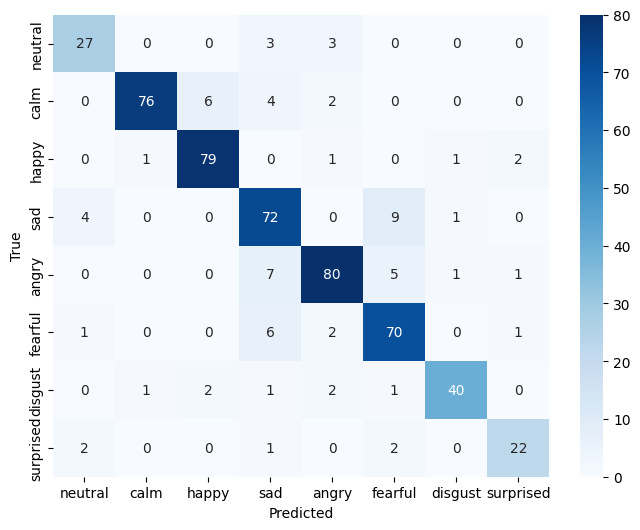

[[27  0  0  3  3  0  0  0]
 [ 0 76  6  4  2  0  0  0]
 [ 0  1 79  0  1  0  1  2]
 [ 4  0  0 72  0  9  1  0]
 [ 0  0  0  7 80  5  1  1]
 [ 1  0  0  6  2 70  0  1]
 [ 0  1  2  1  2  1 40  0]
 [ 2  0  0  1  0  2  0 22]]
Accuracy: 0.8645640074211502
Precision: 0.8693657334271798
Recall: 0.8645640074211502
F1 Score: 0.8656534955134704


In [ ]:
# @title Video Confusion Matrix

preds = []
truths = []
video_save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_video.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
video_model = VideoNet()
video_model.load_state_dict(torch.load(video_save_path))
print(sum(p.numel() for p in video_model.parameters()))
video_model.to(device)
correct = 0
total = 0
video_model.eval()
cntr = 1
criterion = nn.CrossEntropyLoss()
total_loss = 0
with torch.no_grad():
    for batch in test_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)
        outputs = video_model(frames)
        #print(labels)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        #print(predicted)
        preds.append(predicted)
        truths.append(labels)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1


epoch_loss = total_loss / len(test_dataloader)
epoch_acc = correct / total * 100
print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")


preds = torch.cat(preds, dim=0).cpu().numpy()
truths = torch.cat(truths, dim=0).cpu().numpy()
cm = confusion_matrix(truths, preds)
labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']

plt.figure(figsize=(8, 6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.savefig("/content/drive/MyDrive/COSMOSPosterProject/cf_matrix_B.png", dpi=300, bbox_inches='tight')
plt.show()
print(cm)

precision = precision_score(truths, preds, average='weighted')
recall = recall_score(truths, preds, average='weighted')
f1 = f1_score(truths, preds, average='weighted')
accuracy = accuracy_score(truths, preds)

print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')


In [ ]:
max_test_acc = 60.70

In [ ]:
# @title Audio Training
audio_save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_audio.pth'


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
audio_model = AudioNet()
audio_model.load_state_dict(torch.load(audio_save_path))
print(sum(p.numel() for p in audio_model.parameters()))
audio_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_audio = optim.Adam(audio_model.parameters(), lr=0.0005)
num_epochs = 10

for epoch in range(num_epochs):
    audio_model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    cntr = 1
    for batch in audio_train_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)
        spec = spec.unsqueeze(1)
        #print(spec.shape)

        optimizer_audio.zero_grad()
        outputs = audio_model(spec)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_audio.step()
        total_loss += loss.item()
        print(f"Train Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1

    epoch_loss = total_loss / len(audio_train_dataloader)
    epoch_acc = correct / total * 100
    print(f"Train Epoch Loss: {epoch_loss:.4f} | Train Epoch Accuracy: {epoch_acc:.2f}%")

    audio_model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    cntr = 1
    for batch in test_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)
        spec = spec.unsqueeze(1)
        #print(spec.shape)
        optimizer_audio.zero_grad()
        outputs = audio_model(spec)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1

    epoch_loss = total_loss / len(test_dataloader)
    epoch_acc = correct / total * 100
    print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")
    # Save model after each epoch
    if (epoch_acc > max_test_acc):
        torch.save(audio_model.state_dict(), audio_save_path)
        print(f"Model saved to {audio_save_path}")
        max_test_acc = epoch_acc
    else:
        print("Model Ass, not saved!")


263593
Test Batch 1 Loss: 0.3937 | Accuracy: 90.62%
Test Batch 2 Loss: 0.7792 | Accuracy: 78.12%
Test Batch 3 Loss: 1.3151 | Accuracy: 53.12%
Test Batch 4 Loss: 0.6625 | Accuracy: 78.12%
Test Batch 5 Loss: 1.2714 | Accuracy: 50.00%
Test Batch 6 Loss: 1.4297 | Accuracy: 28.12%
Test Batch 7 Loss: 1.6764 | Accuracy: 31.25%
Test Batch 8 Loss: 0.7994 | Accuracy: 71.88%
Test Batch 9 Loss: 1.0384 | Accuracy: 65.62%
Test Batch 10 Loss: 0.5504 | Accuracy: 90.62%
Test Batch 11 Loss: 1.8397 | Accuracy: 31.25%
Test Batch 12 Loss: 1.4598 | Accuracy: 50.00%
Test Batch 13 Loss: 1.0114 | Accuracy: 62.50%
Test Batch 14 Loss: 0.7945 | Accuracy: 78.12%
Test Batch 15 Loss: 1.1427 | Accuracy: 62.50%
Test Batch 16 Loss: 0.7199 | Accuracy: 71.88%
Test Batch 17 Loss: 0.3057 | Accuracy: 96.30%
Test Loss: 1.0112 | Test Accuracy: 63.82%


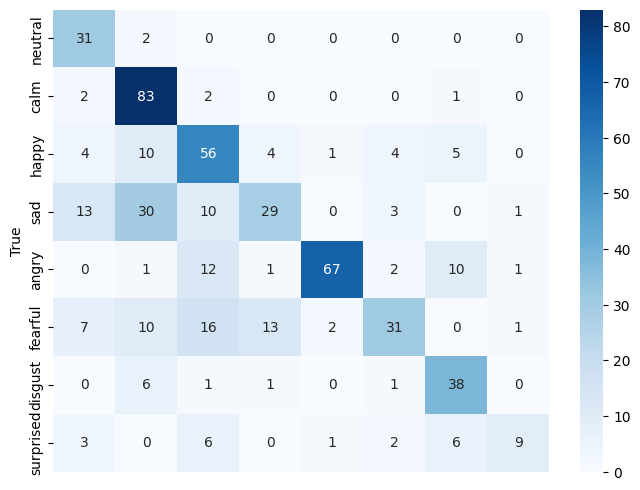

[[31  2  0  0  0  0  0  0]
 [ 2 83  2  0  0  0  1  0]
 [ 4 10 56  4  1  4  5  0]
 [13 30 10 29  0  3  0  1]
 [ 0  1 12  1 67  2 10  1]
 [ 7 10 16 13  2 31  0  1]
 [ 0  6  1  1  0  1 38  0]
 [ 3  0  6  0  1  2  6  9]]
Accuracy: 0.6382189239332097
Precision: 0.672560605914091
Recall: 0.6382189239332097
F1 Score: 0.6225536135920996


In [ ]:
# @title Audio Confusion Matrix

preds = []
truths = []
audio_save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_audio.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
audio_model = AudioNet()
audio_model.load_state_dict(torch.load(audio_save_path))
print(sum(p.numel() for p in audio_model.parameters()))
audio_model.to(device)
correct = 0
total = 0
audio_model.eval()
cntr = 1
criterion = nn.CrossEntropyLoss()
total_loss = 0
with torch.no_grad():
    for batch in test_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)
        spec = spec.unsqueeze(1)
        outputs = audio_model(spec)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        preds.append(predicted)
        truths.append(labels)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1


epoch_loss = total_loss / len(test_dataloader)
epoch_acc = correct / total * 100
print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")


preds = torch.cat(preds, dim=0).cpu().numpy()
truths = torch.cat(truths, dim=0).cpu().numpy()
cm = confusion_matrix(truths, preds)
labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']

plt.figure(figsize=(8, 6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues', yticklabels=labels)
plt.xticks([])
plt.ylabel("True")
plt.savefig("/content/drive/MyDrive/COSMOSPosterProject/cf_matrix_A.png", dpi=300, bbox_inches='tight')
plt.show()
print(cm)

precision = precision_score(truths, preds, average='weighted')
recall = recall_score(truths, preds, average='weighted')
f1 = f1_score(truths, preds, average='weighted')
accuracy = accuracy_score(truths, preds)

print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')


In [ ]:
ptorch.cuda.empty_cache()
import gc
gc.collect()

0

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
audio_model = AudioNet()
audio_model.load_state_dict(torch.load('/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_audio.pth'))
audio_model.to(device)
video_model = VideoNet()
video_model.load_state_dict(torch.load('/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_video.pth'))
video_model.to(device)

train_audio_outputs = []
train_video_outputs = []
test_audio_outputs = []
test_video_outputs = []
train_labels = []
test_labels = []

In [ ]:
print(len(test_audio_outputs))

In [ ]:
test_video_outputs.shape

AttributeError: 'list' object has no attribute 'shape'

In [ ]:
# @title KNN initialization
import torch.nn.functional as F
preds = []
truths = []
video_save_path = '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_video.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
video_model = VideoNet()
video_model.load_state_dict(torch.load(video_save_path))
print(sum(p.numel() for p in video_model.parameters()))
video_model.to(device)
correct = 0
total = 0
video_model.train()
cntr = 1
criterion = nn.CrossEntropyLoss()
total_loss = 0
with torch.no_grad():
    for batch in video_train_dataloader:
        if batch is None:
            continue  # skip bad batch
        frames, spec, labels = batch
        frames = frames.to(device)
        spec = spec.to(device)
        labels = labels.to(device)
        spec = spec.unsqueeze(1)
        outputs = video_model(frames)
        #print(labels)

        # Accuracy
        _, predicted = torch.max(outputs, 1)

        #print(predicted)
        preds.append(F.softmax(outputs, dim=1))
        truths.append(labels)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        # Loss
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        print(f"Test Batch {cntr} Loss: {loss.item():.4f} | Accuracy: {(predicted == labels).sum().item()/labels.size(0) * 100:.2f}%")

        # (Optional) Output logging — softmax predictions
        #probs = F.softmax(outputs, dim=1)
        # print(f"Predicted probs: {probs.detach().cpu().numpy()}")
        cntr += 1


epoch_loss = total_loss / len(test_dataloader)
epoch_acc = correct / total * 100
print(f"Test Loss: {epoch_loss:.4f} | Test Accuracy: {epoch_acc:.2f}%")


preds = torch.cat(preds, dim=0).view(-1).cpu().numpy()
truths = torch.cat(truths, dim=0).view(-1).cpu().numpy()

train_video_outputs = preds
train_labels = truths



1278184
Test Batch 1 Loss: 0.1449 | Accuracy: 93.75%
Test Batch 2 Loss: 0.1268 | Accuracy: 93.75%
Test Batch 3 Loss: 0.0228 | Accuracy: 100.00%
Test Batch 4 Loss: 0.0543 | Accuracy: 100.00%
Test Batch 5 Loss: 0.0580 | Accuracy: 96.88%
Test Batch 6 Loss: 0.1227 | Accuracy: 96.88%
Test Batch 7 Loss: 0.1300 | Accuracy: 93.75%
Test Batch 8 Loss: 0.0164 | Accuracy: 100.00%
Test Batch 9 Loss: 0.0881 | Accuracy: 96.88%
Test Batch 10 Loss: 0.0643 | Accuracy: 96.88%
Test Batch 11 Loss: 0.2139 | Accuracy: 93.75%
Test Batch 12 Loss: 0.0687 | Accuracy: 96.88%
Test Batch 13 Loss: 0.0531 | Accuracy: 96.88%
Test Batch 14 Loss: 0.1231 | Accuracy: 96.88%
Test Batch 15 Loss: 0.0779 | Accuracy: 96.88%
Test Batch 16 Loss: 0.0907 | Accuracy: 93.75%
Test Batch 17 Loss: 0.0509 | Accuracy: 100.00%
Test Batch 18 Loss: 0.0687 | Accuracy: 96.88%
Test Batch 19 Loss: 0.0797 | Accuracy: 96.88%
Test Batch 20 Loss: 0.1483 | Accuracy: 96.88%
Test Batch 21 Loss: 0.1248 | Accuracy: 90.62%
Test Batch 22 Loss: 0.0375 | Ac

(1601, 8)
(1601, 8)
(539, 8)
Accuracy: 0.9128014842300557
Precision: 0.9126274778675958
Recall: 0.9128014842300557
F1 Score: 0.9120712192170565


/usr/local/lib/python3.11/dist-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


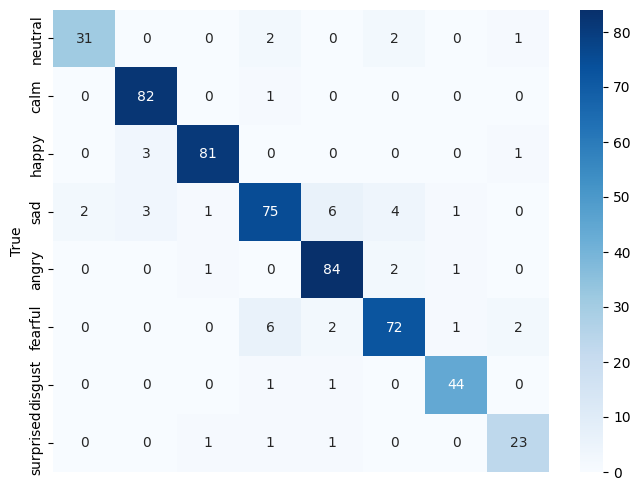

[[31  0  0  2  0  2  0  1]
 [ 0 82  0  1  0  0  0  0]
 [ 0  3 81  0  0  0  0  1]
 [ 2  3  1 75  6  4  1  0]
 [ 0  0  1  0 84  2  1  0]
 [ 0  0  0  6  2 72  1  2]
 [ 0  0  0  1  1  0 44  0]
 [ 0  0  1  1  1  0  0 23]]


In [ ]:
total_outputs = np.array([(train_audio_outputs[i] + train_video_outputs[i])/2 for i in range(len(train_audio_outputs))]).reshape(-1,8)
print(total_outputs.shape)
train_labels = np.array(train_labels).reshape(-1,1)
print(total_outputs.shape)
knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(total_outputs, train_labels)
import pickle
# Its important to use binary mode
knnPickle = open('/content/drive/MyDrive/COSMOSPosterProject/knnpickle_file', 'wb')

# source, destination
pickle.dump(knn, knnPickle)

# close the file
knnPickle.close()

total_outputs = np.array([(test_audio_outputs[i] + test_video_outputs[i])/2 for i in range(len(test_audio_outputs))]).reshape(-1,8)
print(total_outputs.shape)
test_labels = np.array(test_labels).reshape(-1,1)

truths = knn.predict(total_outputs)
preds = test_labels

precision = precision_score(truths, preds, average='weighted')
recall = recall_score(truths, preds, average='weighted')
f1 = f1_score(truths, preds, average='weighted')
accuracy = accuracy_score(truths, preds)

print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')

cm = confusion_matrix(knn.predict(total_outputs), test_labels)
labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']

plt.figure(figsize=(8, 6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues', yticklabels=labels)
plt.xticks([])

plt.ylabel("True")
plt.savefig("/content/drive/MyDrive/COSMOSPosterProject/cf_matrix_C.png", dpi=300, bbox_inches='tight')
plt.show()
print(cm)

In [ ]:
torch.save(audio_model.state_dict(), '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_audio.pth')
torch.save(video_model.state_dict(), '/content/drive/MyDrive/COSMOSPosterProject/EmoNet2_video.pth')

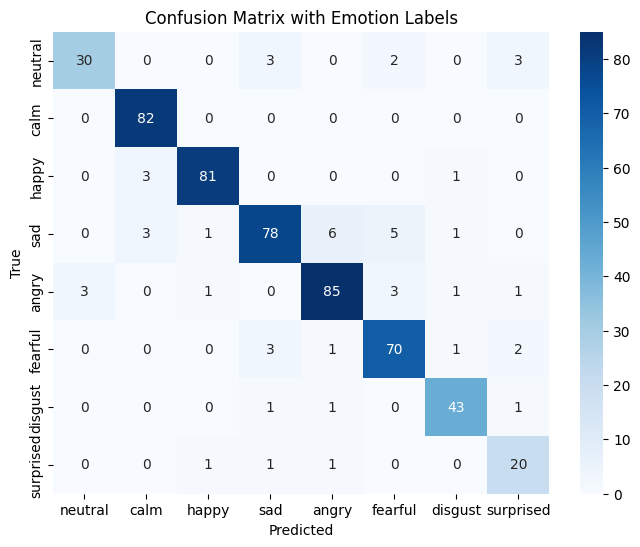

[[30  0  0  3  0  2  0  3]
 [ 0 82  0  0  0  0  0  0]
 [ 0  3 81  0  0  0  1  0]
 [ 0  3  1 78  6  5  1  0]
 [ 3  0  1  0 85  3  1  1]
 [ 0  0  0  3  1 70  1  2]
 [ 0  0  0  1  1  0 43  1]
 [ 0  0  1  1  1  0  0 20]]


In [ ]:
print(accuracy_score(knn.predict(total_outputs), test_labels))
print(precision_score(knn.predict(total_outputs), test_labels, average='weighted'))
print(recall_score(knn.predict(total_outputs), test_labels, average='weighted'))
print(f1_score(knn.predict(total_outputs), test_labels, average='weighted'))

0.9072356215213359
0.9084819824533122
0.9072356215213359
0.9067988308117664


In [ ]:
tao = []
for v in test_audio_outputs:
    for x in v:
        tao.append(x)
print(torch.tensor(tao).shape)

torch.Size([1824])


In [ ]:
tvo = []
for v in test_audio_outputs:
    for x in v:
        tvo.append(x)
print(torch.tensor(tvo).shape)

torch.Size([1824])


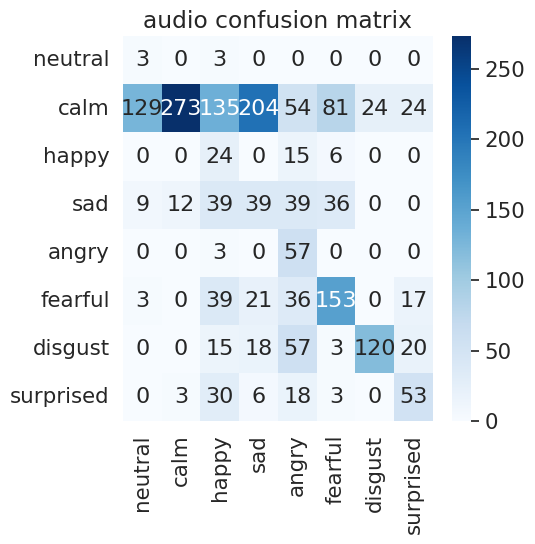

In [ ]:
pd.options.display.float_format = '{:.2f}'.format
df_cm = pd.DataFrame(x, index = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"],
                        columns = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"])

plt.figure(figsize = (5,5))
plt.title('audio confusion matrix')
sn.set(font_scale=1.4)
sn.heatmap(df_cm, annot=True, annot_kws={"size": 16}, fmt='g', cmap='Blues')
plt.show()

In [ ]:
train_correct_audio = [i for i in np.load(arr_pth + '/wa/train_acc_audio_wa.npy')]
train_correct_video = [i for i in np.load(arr_pth + '/wa/train_acc_video_wa.npy')]
train_correct_custom = [i for i in np.load(arr_pth + '/wa/train_acc_custom_wa.npy')]
test_correct_audio = [i for i in np.load(arr_pth + '/wa/test_acc_audio_wa.npy')]
test_correct_video = [i for i in np.load(arr_pth + '/wa/test_acc_video_wa.npy')]
test_correct_custom = [i for i in np.load(arr_pth + '/wa/test_acc_custom_wa.npy')]

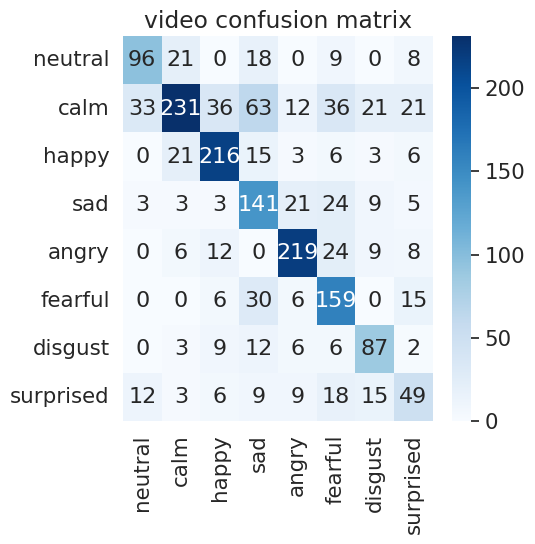

In [ ]:
pd.options.display.float_format = '{:.2f}'.format
df_cm = pd.DataFrame(x1, index = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"],
                        columns = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"])

plt.figure(figsize = (5,5))
plt.title('video confusion matrix')
sn.set(font_scale=1.4)
sn.heatmap(df_cm, annot=True, annot_kws={"size": 16}, fmt='g', cmap='Blues')
plt.show()


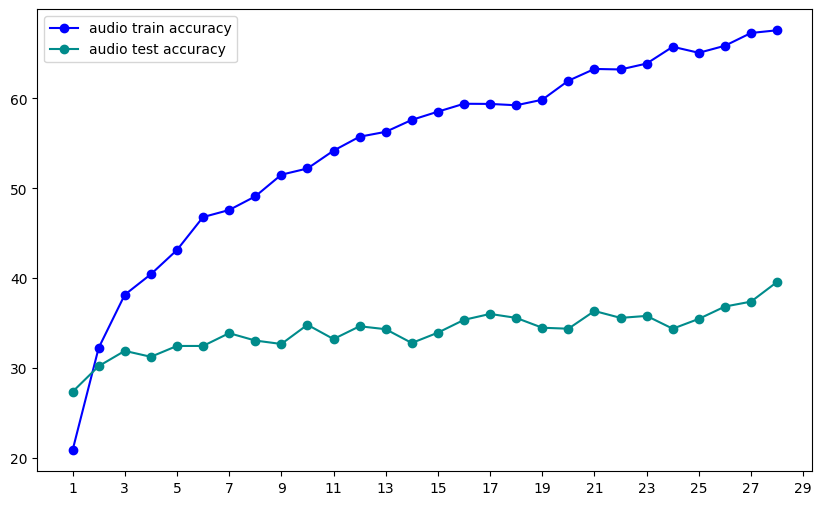

In [ ]:
plt.figure(figsize=(10,6))
plt.xticks(np.arange(min(range(1, len(train_correct_audio)+1)), max(range(1, len(train_correct_audio)+1))+2, step=2))
plt.yticks(np.arange(20, 80, step=10))
plt.plot(range(1, len(train_correct_audio)+1), train_correct_audio,  '-bo', label='audio train accuracy')
plt.plot(range(1, len(test_correct_audio)+1), test_correct_audio, linestyle='-', color='darkcyan', marker='o', label = 'audio test accuracy')
plt.legend()

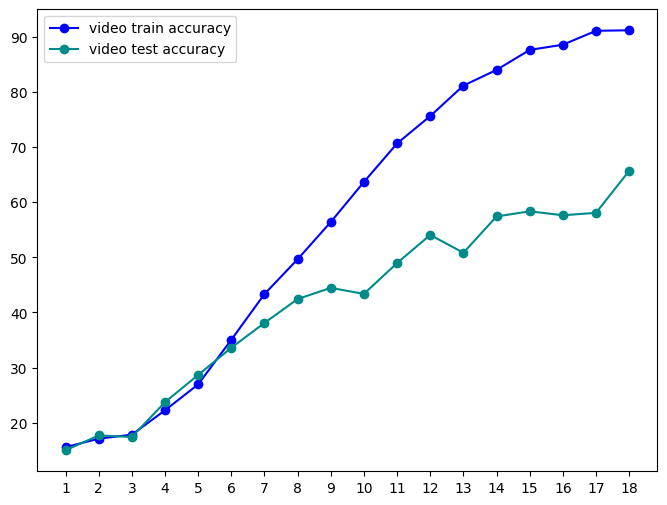

In [ ]:
plt.figure(figsize=(8,6))
plt.yticks(np.arange(20, 95, step=10))
plt.xticks(np.arange(min(range(1, len(train_correct_video)+1)), max(range(1, len(train_correct_video)+1))+2, step=1))
plt.plot(range(1, len(train_correct_video)+1), train_correct_video,  '-bo', label='video train accuracy')
plt.plot(range(1, len(test_correct_video)+1), test_correct_video, linestyle='-', color='darkcyan', marker='o', label = 'video test accuracy')
plt.legend()

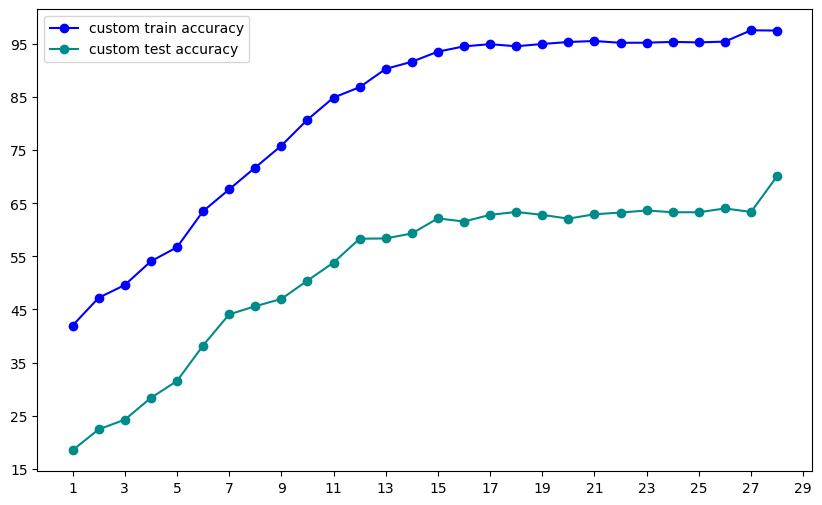

In [ ]:
plt.figure(figsize=(10,6))
plt.xticks(np.arange(min(range(1, len(train_correct_custom)+1)), max(range(1, len(train_correct_custom)+1))+2, step=2))
plt.yticks(np.arange(5, int(max(np.array(train_correct_custom)*100))+5, step=10))
plt.plot(range(1, len(train_correct_custom)+1), np.array(train_correct_custom)*100,  '-bo', label='custom train accuracy')
plt.plot(range(1, len(test_correct_custom)+1), np.array(test_correct_custom)*100, linestyle='-', color='darkcyan', marker='o', label = 'custom test accuracy')
plt.legend()

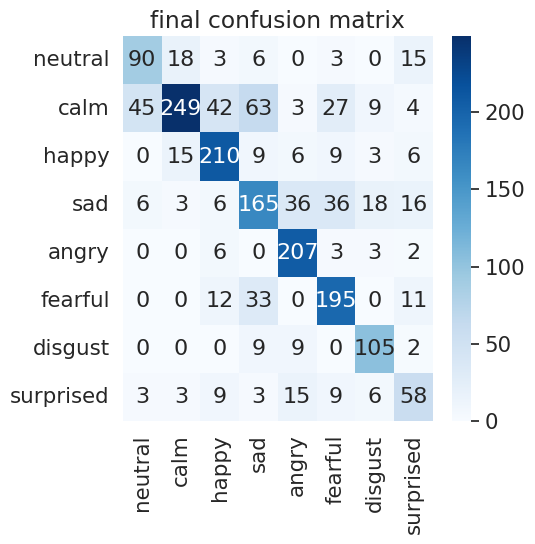

In [ ]:
pd.options.display.float_format = '{:.2f}'.format
df_cm = pd.DataFrame(cm, index = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"],
                        columns = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"])

plt.figure(figsize = (5,5))
plt.title('final confusion matrix')
sn.set(font_scale=1.4)
sn.heatmap(df_cm, annot=True, annot_kws={"size": 16}, fmt='g', cmap='Blues')
plt.show()

In [ ]:
import numpy as np
from enum import Enum
import random

class MoveType(Enum):
    top_left = (0,0)
    top_center = (0,1)
    top_right = (0,2)

    middle_left = (1,0)
    middle_center = (3,1)
    middle_right = (1,2)

    bottom_left = (2,0)
    bottom_center = (2,1)
    bottom_right = (2,2)

class CellStatus(Enum):
    EMPTY = 0
    USER = 1
    COMPUTER = 2

MARKERS = {0 : " ",
           1 : "X",
           2 : "O"}

class TicTacToe:
    """Class representing a game of Tic Tac Toe."""

    def __init__(self):
        """Init instance of Tic Tac Toe."""
        self.board = np.zeros([3,3])
        self.valid_moves = [move.value for move in MoveType]
        self.print_instructions()
        self.play_game()

    def print_instructions(self):
        """Print instructions."""
        valid_moves_str = ', '.join([MoveType(move).name for move in self.valid_moves])
        print(f"Welcome to Tic Tac Toe! \nUser input should be one of the moves below: \n{valid_moves_str}")

    def __update_valid_moves(self):
        """Update the list of valid moves remaining."""
        self.valid_moves = [tuple(valid_move) for valid_move in np.argwhere(self.board == 0)]

    def __print_game_board(self):
        """Print game board."""

        # display board with Xs and Os
        disp_board = np.reshape([MARKERS[n] for n in self.board.flatten()], [3,3])

        print('\n')
        print(disp_board)

    def __user_take_turn(self):
        """Prompt the user to take their turn."""
        user_move = input("Please take your turn: ")
        if MoveType[user_move].value in self.valid_moves:
            move_index = MoveType[user_move].value
            self.board[move_index] = CellStatus.USER.value
            self.__update_valid_moves()
            self.__print_game_board()
        else:
            print("Please enter a valid move.")
            self.__user_take_turn()

    def __computer_take_turn(self):
        """Automate the computer's turn."""
        move_index = random.choice(self.valid_moves)
        self.board[move_index] = CellStatus.COMPUTER.value
        self.__update_valid_moves()
        self.__print_game_board()

    def play_game(self):
        """Play a game of Tic Tac Toe until someone wins."""
        end_game = False
        while not end_game:
            self.__user_take_turn()
            end_game, message = self.__check_end_conditions("USER")
            if end_game:
                print(message)


            self.__computer_take_turn()
            end_game, message = self.__check_end_conditions("COMPUTER")
            if end_game:
                print(message)
                break

    def __check_end_conditions(self, player) -> tuple[bool, str]:
        """Check if the game should end."""
        # find player's moves on board
        [player_rows, player_cols] = np.where(self.board == CellStatus[player].value)
        unique_rows, row_counts = np.unique(player_rows, return_counts=True)
        unique_cols, col_counts = np.unique(player_cols, return_counts=True)

        # check win conditions
        row_win = any(row_counts >=3)
        col_win = any(col_counts >=3)
        diag_win = all(np.diagonal(self.board) == CellStatus["USER"].value) | all(np.diagonal(np.fliplr(self.board)) == CellStatus["USER"].value)
        end_game = any([row_win, col_win, diag_win])

        # if player has won
        if end_game:
            if player == "USER":
                message = "You win!"
            elif player == "COMPUTER":
                message = "Computer wins!"

        # if there are valid moves remaining
        elif len(self.valid_moves) == 0:
            end_game = True
            message = "No valid moves remaining."

        # assign empty string if the game continues
        else:
            message = ""
        return end_game, message
TicTacToe()

Welcome to Tic Tac Toe! 
User input should be one of the moves below: 
top_left, top_center, top_right, middle_left, middle_center, middle_right, bottom_left, bottom_center, bottom_right
Please take your turn: top_left


[['X' ' ' ' ']
 [' ' ' ' ' ']
 [' ' ' ' ' ']]


[['X' 'O' ' ']
 [' ' ' ' ' ']
 [' ' ' ' ' ']]
Please take your turn: top_right


[['X' 'O' 'X']
 [' ' ' ' ' ']
 [' ' ' ' ' ']]


[['X' 'O' 'X']
 [' ' ' ' ' ']
 ['O' ' ' ' ']]
Please take your turn: middle_center
Please enter a valid move.
Please take your turn: middle_center
Please enter a valid move.
Please take your turn: middle_right


[['X' 'O' 'X']
 [' ' ' ' 'X']
 ['O' ' ' ' ']]


[['X' 'O' 'X']
 [' ' ' ' 'X']
 ['O' 'O' ' ']]
Please take your turn: bottom_center
Please enter a valid move.
Please take your turn: bottom_right


[['X' 'O' 'X']
 [' ' ' ' 'X']
 ['O' 'O' 'X']]
You win!


[['X' 'O' 'X']
 [' ' 'O' 'X']
 ['O' 'O' 'X']]
Computer wins!
